In [ ]:
!pip install kaggle

In [ ]:
!mkdir ~/.kaggle

In [ ]:
!cp kaggle.json ~/.kaggle/kaggle.json

In [ ]:
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d snehilsanyal/construction-site-safety-image-dataset-roboflow

 90% 185M/206M [00:01<00:00, 145MB/s]
100% 206M/206M [00:01<00:00, 145MB/s]


In [ ]:
!unzip /content/construction-site-safety-image-dataset-roboflow.zip

Streaming output truncated to the last 5000 lines.
  inflating: css-data/train/images/IMG_3100_mp4-25_jpg.rf.0a21e9e91348b61c6c1483d6884d2135.jpg  
  inflating: css-data/train/images/IMG_3100_mp4-25_jpg.rf.3313bb2b19a7aa3a0af745abe858ec8e.jpg  
  inflating: css-data/train/images/IMG_3100_mp4-25_jpg.rf.3bbcfef23f20b2cf747256793dcfc615.jpg  
  inflating: css-data/train/images/IMG_3100_mp4-25_jpg.rf.6cee1b67a21808fad2318593379f9986.jpg  
  inflating: css-data/train/images/IMG_3100_mp4-25_jpg.rf.ddd7840e3d846cddfcc13d99f4a6999b.jpg  
  inflating: css-data/train/images/IMG_3100_mp4-2_jpg.rf.4d46f38425296af74814d1f0506575b4.jpg  
  inflating: css-data/train/images/IMG_3100_mp4-2_jpg.rf.58de1db8826e4221df63fd980b823844.jpg  
  inflating: css-data/train/images/IMG_3100_mp4-2_jpg.rf.87e69eb0f5f24cbadcca3fbfe8ca029c.jpg  
  inflating: css-data/train/images/IMG_3100_mp4-2_jpg.rf.bde377ae23066dfe925f09789c2bbdef.jpg  
  inflating: css-data/train/images/IMG_3100_mp4-2_jpg.rf.c28f7521c16c937d5b308d1

In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 715.4/715.4 kB 7.5 MB/s eta 0:00:00


In [ ]:
import os
import cv2
import glob
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from ultralytics import YOLO

In [ ]:
import warnings
warnings.filterwarnings('ignore')
np.random.seed(12345)

In [ ]:
dataDir = 'css-data/'
workingDir = '/content/'

In [ ]:
num_classes = 10
classes = ['Hardhat', 'Mask', 'NO-Hardhat', 'NO-Mask', 'NO-Safety Vest', 'Person', 'Safety Cone', 'Safety Vest', 'machinery', 'vehicle']

In [ ]:
file_dict = {
    'train': os.path.join(dataDir, 'train'),
    'val': os.path.join(dataDir, 'valid'),
    'test': os.path.join(dataDir, 'test'),
    'nc': num_classes,
    'names': classes
}

In [ ]:
#writes the dictionary file_dict to the file data.yaml
with open(os.path.join(workingDir, 'data.yaml'), 'w+') as f:
  yaml.dump(file_dict, f)

In [ ]:
class_idx = {str(i):classes[i] for i in range(num_classes)} #maps the class index to the class name
class_stat = {} #statistics about each class
data_len = {} #store number of samples for each class.

In [ ]:
for mode in ['train', 'valid', 'test']:
  class_count = {classes[i]:0 for i in range(num_classes)}
  path = os.path.join(dataDir, mode, 'labels')
  for file in os.listdir(path):

    with open(os.path.join(path, file)) as f:
      lines = f.readlines()
      for cls in set([line[0] for line in lines]):
        class_count[class_idx[cls]] += 1
  data_len[mode] = len(os.listdir(path)) ##stores total no.of samples for each mode
  class_stat[mode] = class_count #counts the number of samples for each class, and stores this information

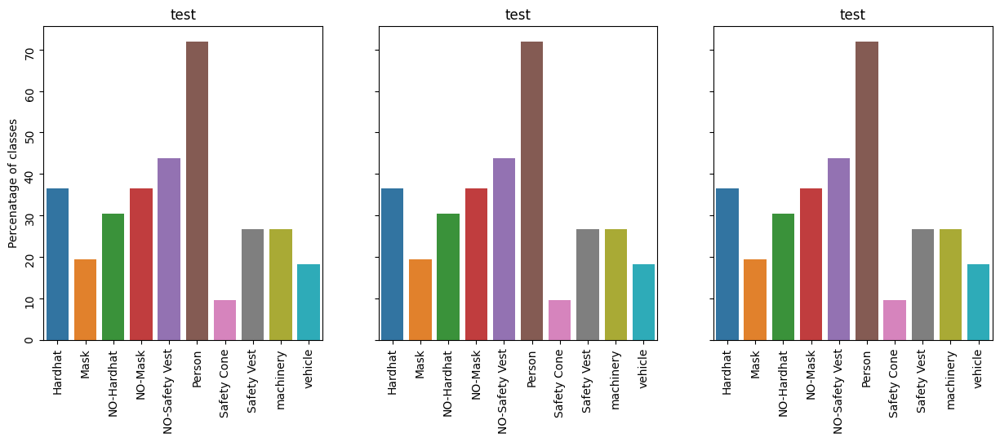

In [ ]:
fig, ax = plt.subplots(1,3, figsize=(15, 5), sharey=True)

for i, model in enumerate(['train', 'valid', 'test']):
  sns.barplot(pd.DataFrame({mode:class_stat[mode]}).T/data_len[mode]*100, ax=ax[i])
  ax[i].set_title(mode)
  ax[i].tick_params(rotation=90)
  ax[i].set_ylabel('Percenatage of classes')
plt.show()

In [ ]:
#printing the unique sizes of the images found
for mode in ['train', 'valid', 'test']:
  print(f' \nImage sizes in {mode} set:\n')
  image_size = 0
  for file in glob.glob(os.path.join(dataDir, mode, 'images', '*')):
    image = Image.open(file)
    if image.size != image_size:
      print(image.size)
      image_size = image.size

 
Image sizes in train set:

(640, 640)
 
Image sizes in valid set:

(640, 640)
 
Image sizes in test set:

(640, 640)


In [ ]:
for mode in ['train', 'valid', 'test']:
  files = glob.glob(os.path.join(dataDir, mode, 'images','*'))
  print(f'{mode} set size: {len(files)}\n')

train set size: 2605

valid set size: 114

test set size: 82



In [ ]:
model = YOLO('yolov8n.pt')

In [ ]:
model.train(data=os.path.join(workingDir, 'data.yaml'),
            task = 'detect',
            imgsz = 640,
            epochs = 1,
            batch = 32,
            mode = 'train',
            name = 'yolov8_trained_model')

Ultralytics YOLOv8.1.16 🚀 Python-3.10.12 torch-2.1.0+cu121 CPU (Intel Xeon 2.20GHz)
engine/trainer: task=detect, mode=train, model=yolov8n.pt, data=/content/data.yaml, epochs=1, time=None, patience=100, batch=32, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=yolov8_trained_model3, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=False, save_crop=False, show_labels=True, show_conf=True, s

train: Scanning /content/css-data/train/labels.cache... 2605 images, 6 backgrounds, 0 corrupt: 100%|██████████| 2605/2605 [00:00<?, ?it/s]

train: WARNING ⚠️ /content/css-data/train/images/004720_jpg.rf.afc486560a4004c7cfd67910af31a29c.jpg: 1 duplicate labels removed
train: WARNING ⚠️ /content/css-data/train/images/construction-813-_jpg.rf.b085952261fd98f2e76b8065de149b5f.jpg: 1 duplicate labels removed


albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01), CLAHE(p=0.01, clip_limit=(1, 4.0), tile_grid_size=(8, 8))


val: Scanning /content/css-data/valid/labels.cache... 114 images, 10 backgrounds, 0 corrupt: 100%|██████████| 114/114 [00:00<?, ?it/s]

...

        1/1         0G      1.397      2.999      1.497        353        640: 100%|██████████| 82/82 [41:15<00:00, 30.19s/it]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 2/2 [00:41<00:00, 20.72s/it]


                   all        114        697       0.42      0.316      0.323      0.142

1 epochs completed in 0.702 hours.
Optimizer stripped from runs/detect/yolov8_trained_model3/weights/last.pt, 6.2MB
Optimizer stripped from runs/detect/yolov8_trained_model3/weights/best.pt, 6.2MB

Validating runs/detect/yolov8_trained_model3/weights/best.pt...
Ultralytics YOLOv8.1.16 🚀 Python-3.10.12 torch-2.1.0+cu121 CPU (Intel Xeon 2.20GHz)
Model summary (fused): 168 layers, 3007598 parameters, 0 gradients, 8.1 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 2/2 [00:33<00:00, 16.98s/it]


                   all        114        697      0.421      0.317      0.323      0.142
               Hardhat        114         79       0.88      0.519      0.648      0.349
                  Mask        114         21      0.398      0.476      0.466      0.157
            NO-Hardhat        114         69        0.2      0.203      0.125     0.0362
               NO-Mask        114         74          0          0     0.0974     0.0295
        NO-Safety Vest        114        106      0.555     0.0707      0.213     0.0798
                Person        114        166      0.444      0.572      0.528      0.285
           Safety Cone        114         44      0.716       0.25      0.365      0.151
           Safety Vest        114         41      0.514      0.361      0.379       0.13
             machinery        114         55      0.134      0.618       0.27       0.13
               vehicle        114         42      0.372     0.0952      0.137     0.0743
Speed: 2.5ms preproce

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ab303f62140>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.0

Getting the Best model

In [ ]:
model = YOLO('runs/detect/yolov8_trained_model/weights/best.pt')

Predictions

In [ ]:
results = model.predict(source=os.path.join(dataDir, 'test', 'images'), save = True)


image 1/82 /content/css-data/test/images/-4405-_png_jpg.rf.82b5c10b2acd1cfaa24259ada8e599fe.jpg: 640x640 1 Hardhat, 1 Person, 446.4ms
image 2/82 /content/css-data/test/images/000005_jpg.rf.96e9379ccae638140c4a90fc4b700a2b.jpg: 640x640 2 Hardhats, 2 NO-Masks, 2 Persons, 360.3ms
image 3/82 /content/css-data/test/images/002551_jpg.rf.ce4b9f934161faa72c80dc6898d37b2d.jpg: 640x640 2 Hardhats, 3 NO-Masks, 2 NO-Safety Vests, 3 Persons, 353.5ms
image 4/82 /content/css-data/test/images/003357_jpg.rf.9867f91e88089bb68dc95947d5116d14.jpg: 640x640 1 Hardhat, 2 NO-Masks, 1 NO-Safety Vest, 1 Person, 1 Safety Cone, 406.7ms
image 5/82 /content/css-data/test/images/004063_jpg.rf.1b7cdc4035bcb24ef69b8798b444053e.jpg: 640x640 4 Hardhats, 1 NO-Hardhat, 4 NO-Safety Vests, 6 Persons, 2 Safety Vests, 692.6ms
image 6/82 /content/css-data/test/images/004763_jpg.rf.46484e6ca73caeaa9de45822cf1085a9.jpg: 640x640 3 Hardhats, 5 NO-Masks, 3 NO-Safety Vests, 3 Persons, 577.5ms
image 7/82 /content/css-data/test/image

**Print predictions**

In [ ]:
pred = glob.glob('/content/runs/detect/predict/*')
n = 5
num_rows = len(pred) // n

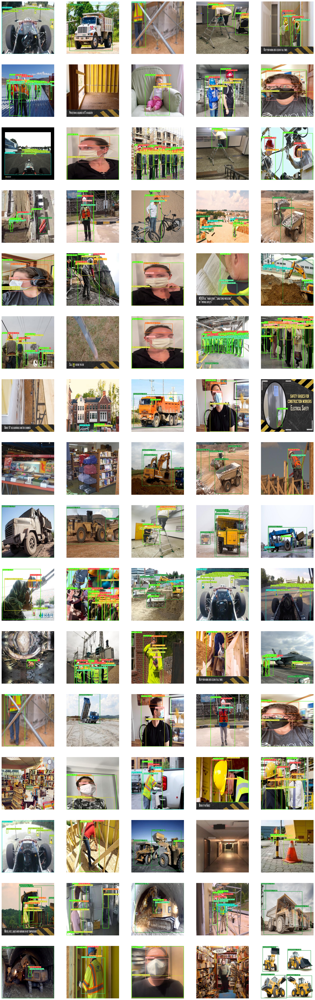

In [ ]:
fig, axs = plt.subplots(num_rows, n, figsize=(25, 5*num_rows)) #rows in the grid, columns;  The axs variable is a list of axes objects, one for each subplot in the grid.
#The figsize parameter specifies the size of the figure in inches (width, height).
for i in range(num_rows): #iterates over the rows in the grid
    for j in range(n): #iterates over the columns in the current row
        idx = i*n + j  # Calculate the index of the image to display based on the current row (i) and column (j).
        if idx < len(pred): #checks if the index is within the range of the pred list. This is necessary because there may not be enough images in the pred list to fill the entire grid.
            image = Image.open(pred[idx]) #opens the image file corresponding to the current index (idx) in the pred list using the Image.open() function.
            axs[i, j].imshow(image) #displays the image on the current subplot (axs[i, j])
            axs[i, j].grid(False) #turns off the grid lines for the current subplot.
            axs[i, j].axis('off') #turns off the axis labels and ticks for the current subplot, making the image appear without any axis information.
plt.show()